# Score: finite differences vs analytical gradient

## Definitions

$$
\log \phi_{i,1} = \log \phi_{\text{pop},1} + \beta\, c_i + \eta_{i,1},
\qquad
\log \phi_{i,2} = \log \phi_{\text{pop},2} + \eta_{i,2},
\qquad
\eta_i \sim \mathcal N(0, \Omega),
\qquad
\Omega = \begin{pmatrix} \omega_1^2 & \rho\,\omega_1\omega_2 \\ \rho\,\omega_1\omega_2 & \omega_2^2 \end{pmatrix},
\qquad
n_{\text{pdu}} = 2
\tag{1}
$$
$$
y_{ij} \sim \mathcal N\big(1,\ \sigma^2\big),
\qquad
j = 1, \dots, n_i \ \text{(number of observations of patient } i\text{)}
\tag{2}
$$

$$
g_{ik}^{(m)} = \frac{\partial}{\partial\theta_k}\log p\big(y_i, \phi_i^{(m)};\theta\big)
\tag{3}
$$

$$
z_{i,k} = \frac{\eta_{i,k}}{\omega_k}
\tag{4}
$$

$$
(\Omega^{-1}\eta_i)_k = \frac{z_{i,k} - \rho\, z_{i,l}}{(1-\rho^2)\,\omega_k},
\qquad
l \neq k
\tag{5}
$$

## Derivatives

$\phi_i$ fixed:

$$
\log p(y_i, \phi_i;\theta) = -\frac{n_{\text{pdu}}}{2}\log 2\pi - \frac12\log|\Omega| - \frac12\,\eta_i^\top\Omega^{-1}\eta_i
- \frac{n_i}{2}\log 2\pi - \frac{n_i}{2}\log\sigma^2 - \frac{1}{2\sigma^2}\sum_j (y_{ij}-1)^2
\tag{6}
$$

$$
|\Omega| = \omega_1^2\omega_2^2(1-\rho^2),
\qquad
\eta_i^\top\Omega^{-1}\eta_i = \frac{A_i}{1-\rho^2},
\qquad
A_i = z_{i,1}^2 - 2\rho\, z_{i,1} z_{i,2} + z_{i,2}^2
\tag{7}
$$

Then :

$$
\frac{\partial \log p}{\partial \eta_i} = -\Omega^{-1}\eta_i,
\qquad
\frac{\partial \eta_{i,k}}{\partial \phi_{\text{pop},k}} = -\frac{1}{\phi_{\text{pop},k}},
\qquad
\frac{\partial \eta_{i,1}}{\partial \beta} = -c_i,
\qquad
\frac{\partial z_{i,k}}{\partial \omega_k} = -\frac{z_{i,k}}{\omega_k},
\qquad
\frac{\partial A_i}{\partial z_{i,k}} = 2\,(z_{i,k} - \rho\, z_{i,l})
\tag{8}
$$
Finally :
$$
\frac{\partial \log p}{\partial\phi_{\text{pop},k}} = \frac{(\Omega^{-1}\eta_i)_k}{\phi_{\text{pop},k}}
\tag{9}
$$

$$
\frac{\partial \log p}{\partial\beta} = (\Omega^{-1}\eta_i)_1\, c_i
\tag{10}
$$

$$
\frac{\partial \log p}{\partial\omega_k} = -\frac1{\omega_k} + \frac{z_{i,k}\,(z_{i,k} - \rho\, z_{i,l})}{(1-\rho^2)\,\omega_k}
\tag{11}
$$

$$
\frac{\partial \log p}{\partial\rho} = \frac{\rho}{1-\rho^2} + \frac{z_{i,1} z_{i,2}}{1-\rho^2} - \frac{\rho\, A_i}{(1-\rho^2)^2}
\tag{12}
$$

$$
\frac{\partial \log p}{\partial\,\text{mi}_1} = 0
\tag{13}
$$

$$
\frac{\partial \log p}{\partial\sigma} = -\frac{n_i}{\sigma} + \frac{\sum_j (y_{ij}-1)^2}{\sigma^3}
\tag{14}
$$

In [1]:
import numpy as np
import pandas as pd
import torch
from pandera.typing import DataFrame

from vpop_calibration.pynlme.data import ObsData
from vpop_calibration.pynlme.diagnostics import ModelDiagnostics
from vpop_calibration.pynlme.model import StatisticalModel
from vpop_calibration.pynlme.params import MixedEffectParameters
from vpop_calibration.pynlme.score_visualizer import get_displayed_estimates
from vpop_calibration.structural_model.analytical import StructuralAnalytical
from vpop_calibration.utils import seed_everything

seed_everything(0)

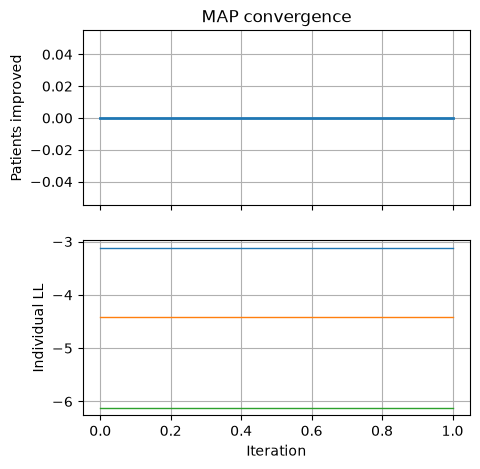

  0%|          | 0/4 [00:00<?, ?it/s]

In [2]:
input_params = MixedEffectParameters.model_validate(
    {
        "model_intrinsic": {"mi_1": {"prior": 2.0}},
        "pdu": {
            "pdu_1": {
                "prior": 3.0,
                "prior_omega": 0.2,
                "covariates": {"c": {"coef_name": "beta_c", "prior": 0.3}},
            },
            "pdu_2": {"prior": 5.0, "prior_omega": 0.1},
        },
        "error_model": {"out_1": {"error_type": "additive", "initial_variance": 0.5}},
    }
)
c_values = {"1": 0.0, "2": 1.0, "3": -2.0} #covariates
df = pd.DataFrame(
    [
        {"id": id, "c": c, "output_name": "out_1", "time": time}
        for id, c in c_values.items()
        for time in [0.0, 1.0, 2.0]
    ]
)
df["value"] = np.random.default_rng(0).normal(1.0, 1.0, len(df))

model = StatisticalModel(
    structural_model=StructuralAnalytical(
        equations=lambda mi_1, pdu_1, pdu_2, t: torch.ones_like(t),
        variable_names=["out_1"],
    ),
    dataset=ObsData(DataFrame(df)),
    input_params=input_params,
)
omega = model.omega_pop.clone()
omega[0, 1] = omega[1, 0] = 0.5 * torch.sqrt(omega[0, 0] * omega[1, 1])
model.set_current_parameters(model.current_params._replace(omega=omega))

diagnostics = ModelDiagnostics(model)
diagnostics.sample_conditional_distribution(nb_samples=5)

scores, names = diagnostics.compute_score_samples()
scores = pd.Series(list(scores.permute(2, 0, 1)), index=names)

In [3]:
estimates = get_displayed_estimates(model)
phi_pop = torch.tensor([estimates["pdu_1"], estimates["pdu_2"]])
omega = torch.tensor([estimates["omega_pdu_1"], estimates["omega_pdu_2"]])
beta, rho, sigma = estimates["beta_c"], estimates["corr_pdu_2_pdu_1"], estimates["sd_add_out_1"]

log_phi = model.convert_etas_to_gaussian_all_patients(
    diagnostics.sampler.total_samples.eta_samples
).cpu()
c = torch.tensor([c_values[id] for id in model.patients], dtype=log_phi.dtype)
nb_obs = torch.tensor([(df["id"] == id).sum() for id in model.patients], dtype=log_phi.dtype)  # (2)
squared_residuals = torch.tensor(
    [((df.loc[df["id"] == id, "value"] - 1.0) ** 2).sum() for id in model.patients],
    dtype=log_phi.dtype,
)

eta = log_phi - torch.log(phi_pop)  # (1)
eta[..., 0] -= beta * c  # (1)
z = eta / omega  # (4)
omega_inv_eta = (z - rho * z.flip(-1)) / ((1 - rho**2) * omega)  # (5)
A = z[..., 0] ** 2 - 2 * rho * z[..., 0] * z[..., 1] + z[..., 1] ** 2  # (7)

analytical = {
    "pdu_1": omega_inv_eta[..., 0] / phi_pop[0],  # (9)
    "pdu_2": omega_inv_eta[..., 1] / phi_pop[1],  # (9)
    "beta_c": omega_inv_eta[..., 0] * c,  # (10)
    "omega_pdu_1": -1 / omega[0] + z[..., 0] * omega_inv_eta[..., 0],  # (11)
    "omega_pdu_2": -1 / omega[1] + z[..., 1] * omega_inv_eta[..., 1],  # (11)
    "corr_pdu_2_pdu_1": rho / (1 - rho**2)
    + z[..., 0] * z[..., 1] / (1 - rho**2)
    - rho * A / (1 - rho**2) ** 2,  # (12)
    "mi_1": torch.zeros_like(c).expand_as(eta[..., 0]),  # (13)
    "sd_add_out_1": (-nb_obs / sigma + squared_residuals / sigma**3).expand_as(eta[..., 0]),  # (14)
}

In [4]:
pd.DataFrame(
    {
        "max |analytical|": {k: v.abs().max().item() for k, v in analytical.items()},
        "max |finite diff - analytical|": {
            k: (scores[k].cpu() - v).abs().max().item() for k, v in analytical.items()
        },
    }
)

,max |analytical|,max |finite diff - analytical|
pdu_1,1.997685,1.536067e-06
pdu_2,1.109559,1.496492e-06
beta_c,5.993054,4.155787e-12
omega_pdu_1,11.781009,2.958133e-05
omega_pdu_2,7.511004,2.567501e-05
corr_pdu_2_pdu_1,1.433844,2.427168e-06
mi_1,0.000000,0.000000e+00
sd_add_out_1,4.504615,1.608032e-05
